# Build a custom filter with Dynestyx

A custom filter plugs into the same `dsx.Filter` handler as a built-in filter. Subclass a config, write the update equations as methods, and implement `gather_outputs` to select what each observation contributes to the result. The inherited `build_filter(model)` binds your methods to each model instance. Dynestyx runs the time loop, constructs posterior distributions, and registers the likelihood when you call `dsx.sample`.

We'll implement the same Gauss–Hermite algorithm twice: once with split prediction and update methods, and once with Cuthbert-style prepare and combine methods. Both versions expose the innovation as a custom diagnostic. We check them against each other and an exact Kalman filter. We then compare state estimates on the univariate nonstationary growth benchmark, where the observation gives the magnitude of a latent state but leaves its sign ambiguous.

In [1]:
from dataclasses import dataclass
from functools import lru_cache
from typing import NamedTuple

import jax
import jax.numpy as jnp
import numpy as np
import numpyro.distributions as dist
from numpyro.handlers import seed, trace
from jaxtyping import PRNGKeyArray
from cuthbertlib.quadrature import gauss_hermite

import dynestyx as dsx
from dynestyx.configs import CombineFilterConfig, SplitFilterConfig, KFConfig, UKFConfig
from dynestyx.inference.filter_interface import FilterInputs, FilterOutputs
from dynestyx.inference.observation_predictions import PredictedObservationOutputs

jax.config.update("jax_enable_x64", True)

## Decide what a step returns

The state is yours to design. This algorithm needs a filtered mean, covariance, and running log likelihood for the next step. It also carries the predictive observation moments and innovation so the gather callback can expose them. Keep the same field shapes at every step for JAX's scan.

In [2]:
class Prior(NamedTuple):
    mean: jax.Array
    cov: jax.Array
    loglik: jax.Array  # Evidence accumulated through the previous observation.


class State(NamedTuple):
    mean: jax.Array
    cov: jax.Array
    loglik: jax.Array
    predictions: PredictedObservationOutputs
    innovation: jax.Array

In [3]:
def gather_outputs(state: State) -> FilterOutputs:
    return FilterOutputs(
        log_normalizing_constant=state.loglik,
        filtered_means=state.mean,
        filtered_covariances=state.cov,
        predicted_observations=state.predictions,
        extra_outputs={"innovation": state.innovation},
    )

`FilterOutputs` is the boundary between your algorithm and Dynestyx. The Gaussian fields become one distribution per observation in `result.dists`. The last cumulative log likelihood becomes `result.marginal_loglik`, and named extras are stacked along observation time. Here the innovation is $y_k-\hat y_{k|k-1}$, so saving it also gives us a way to check that predictions were gathered before assimilation.

## Implement the split interface

Declare the order as a dataclass field. Dynestyx binds the current model to each method, so `predict` can read its transition and `update` can read its observation model. The first observation updates the prior returned by `initialize`. Each later observation gets a prediction and an update. The gather method sees both the prior and the filtered state.

In [4]:
@lru_cache
def quadrature_rule(state_dim: int, order: int):
    return gauss_hermite.weights(state_dim, order=order)


@dataclass(frozen=True, kw_only=True)
class GaussHermiteConfig(SplitFilterConfig[Prior, State]):
    integration_order: int = 3

    def initialize(self, model: dsx.DynamicalModel, inputs: FilterInputs, *, key: PRNGKeyArray | None) -> Prior:
        return initial_prior(model)

    def predict(self, model: dsx.DynamicalModel, filtered: State, inputs: FilterInputs, *, key: PRNGKeyArray | None) -> Prior:
        rule = quadrature_rule(model.state_dim, self.integration_order)
        return predict_prior(model, rule, filtered, inputs)

    def update(self, model: dsx.DynamicalModel, prior: Prior, inputs: FilterInputs, *, key: PRNGKeyArray | None) -> State:
        rule = quadrature_rule(model.state_dim, self.integration_order)
        return update_state(model, rule, prior, inputs)

    def gather_outputs(self, prior: Prior, filtered: State) -> FilterOutputs:
        return gather_outputs(filtered)


split_config = GaussHermiteConfig(integration_order=10)

## Implement the combined interface

Cuthbert separates preparation from combination. `prepare` can package the current inputs before the previous belief is available. Here it just forwards them. `combine` owns the first-step decision and returns a complete filtered state. Its gather callback takes that state as its sole argument. Both subclasses use the same numerical helpers.

In [5]:
@dataclass(frozen=True, kw_only=True)
class CombinedGaussHermiteConfig(CombineFilterConfig[FilterInputs, State]):
    integration_order: int = 3

    def init_prepare(self, model: dsx.DynamicalModel, *, key: PRNGKeyArray | None) -> State:
        prior = initial_prior(model)
        # The initial scan carry has the same structure as every filtered state.
        zero = jnp.zeros(model.observation_dim, dtype=prior.mean.dtype)
        zeros = jnp.outer(zero, zero)
        predictions = PredictedObservationOutputs(mean=zero, cov=zeros, obs_cov=zeros)
        return State(prior.mean, prior.cov, prior.loglik, predictions, zero)

    def filter_prepare(self, model: dsx.DynamicalModel, inputs: FilterInputs, *, key: PRNGKeyArray | None) -> FilterInputs:
        return inputs

    def filter_combine(self, model: dsx.DynamicalModel, filtered: State, inputs: FilterInputs) -> State:
        rule = quadrature_rule(model.state_dim, self.integration_order)
        prior = jax.lax.cond(
            inputs.is_first_step,
            lambda: Prior(filtered.mean, filtered.cov, filtered.loglik),
            lambda: predict_prior(model, rule, filtered, inputs),
        )
        return update_state(model, rule, prior, inputs)

    def gather_outputs(self, filtered: State) -> FilterOutputs:
        return gather_outputs(filtered)


combined_config = CombinedGaussHermiteConfig(integration_order=10)

## Share the numerical steps

This example uses order-ten Gauss–Hermite quadrature. For a Gaussian input, `transform` evaluates the model at weighted points and returns four quantities: the output mean, the covariance of the signal, the average noise covariance, and the state–signal cross-covariance. `update_state` uses them for a Gaussian update and adds the predictive log density of this observation to the running total.

In [6]:
def transform(rule, mean, cov, conditional):
    points = rule.get_sigma_points(mean, jnp.linalg.cholesky(cov))

    def moments(x):
        distribution = conditional(x)
        return distribution.mean, distribution.covariance_matrix

    means, covs = jax.vmap(moments)(points.points)
    signals = points._replace(points=means)
    noise = jnp.einsum("i,ijk->jk", points.wm, covs)
    return signals.mean, signals.covariance(), noise, points.covariance(signals)


def initial_prior(model: dsx.DynamicalModel) -> Prior:
    initial = model.initial_condition
    return Prior(initial.mean, initial.covariance_matrix, jnp.zeros_like(initial.mean[0]))


def predict_prior(model, rule, filtered, inputs):
    def transition(x):
        return model.state_evolution(x, inputs.u_prev, inputs.time_prev, inputs.time)

    mean, signal, noise, _ = transform(rule, filtered.mean, filtered.cov, transition)
    return Prior(mean, signal + noise, filtered.loglik)


def update_state(model, rule, prior, inputs):
    mean, cov, previous_loglik = prior
    y = inputs.y

    def observe(x):
        return model.observation_model(x, inputs.u, inputs.time)

    y_mean, signal, noise, cross = transform(rule, mean, cov, observe)
    y_cov = signal + noise
    gain = jnp.linalg.solve(y_cov, cross.T).T
    innovation = y - y_mean
    return State(
        mean=mean + gain @ innovation,
        cov=cov - gain @ cross.T,
        loglik=previous_loglik + dist.MultivariateNormal(y_mean, y_cov).log_prob(y),
        predictions=PredictedObservationOutputs(mean=y_mean, cov=signal, obs_cov=y_cov),
        innovation=innovation,
    )

## Recover the hidden state in the nonlinear growth benchmark

The univariate nonstationary growth model is a standard nonlinear filtering benchmark. Its transition $x_{k+1}=0.5x_k+25x_k/(1+x_k^2)+8\cos(1.2(k+1))+w_k$ bends sharply near zero. The measurement $y_k=x_k^2/20+v_k$ loses the sign of the state. We use the published noise variances $\mathrm{Var}(w_k)=10$, $\mathrm{Var}(v_k)=1$, and initial prior $x_0\sim\mathcal N(0,5)$. Higher-order quadrature can better resolve how the transition transforms a broad prior. Sign ambiguity can still defeat either Gaussian filter. [Särkkä et al., Section V.C and Figure 8](https://confcats_isif.s3.amazonaws.com/web-files/journals/entries/On%20the%20relation.pdf)

Both implementations use ten Gauss–Hermite points per transform. The default scalar UKF uses three sigma points. We supply the known cosine forcing as a control so all three implementations use the same time-dependent transition. We pass the same control grid to `dsx.simulate` and `dsx.condition`.

In [7]:
times = jnp.arange(101, dtype=float)
controls = (8 * jnp.cos(1.2 * (times + 1)))[:, None]

def growth(x, u, t, t_next):
    return 0.5 * x + 25 * x / (1 + x**2) + u

model = dsx.DynamicalModel(
    control_dim=1,
    initial_condition=dist.MultivariateNormal(jnp.zeros(1), 5 * jnp.eye(1)),
    state_evolution=dsx.GaussianStateEvolution(F=growth, cov=10 * jnp.eye(1)),
    observation_model=dsx.GaussianObservation(h=lambda x, u, t: x**2 / 20, R=jnp.eye(1)),
)

simulation = dsx.simulate(
    model,
    rng_key=jax.random.key(42),
    predict_times=times,
    ctrl_times=times,
    ctrl_values=controls,
    n_simulations=100,
)
truths, observations = simulation.states, simulation.observations
inputs = dict(obs_times=times, ctrl_times=times, ctrl_values=controls)
data = dict(**inputs, obs_values=observations[0])
configs = {"Split": split_config, "Combined": combined_config}
results = {}
for name, config in configs.items():
    with dsx.Filter(config):
        results[name] = dsx.condition("x", model, **data)

split, combined = results["Split"], results["Combined"]
# Compare the entire gathered history, including covariances, diagnostics, and evidence.
assert jax.tree.structure(split.states) == jax.tree.structure(combined.states)
for left, right in zip(jax.tree.leaves(split.states), jax.tree.leaves(combined.states), strict=True):
    np.testing.assert_allclose(left, right, atol=1e-5)
np.testing.assert_allclose(split.extra_outputs["innovation"],
                           data["obs_values"] - split.predicted_observations.mean, atol=1e-5)
for name, result in results.items():
    print(name, "filtered mean at the final observation:", result.dists[-1].mean)

Split filtered mean at the final observation: [16.57595122]
Combined filtered mean at the final observation: [16.57595122]


In [8]:
for name, config in configs.items():
    with trace() as sites, seed(rng_seed=0), dsx.Filter(config):
        dsx.sample("x", model, **data)
    factor = sites["x_marginal_log_likelihood"]["fn"].log_factor
    np.testing.assert_allclose(factor, results[name].marginal_loglik, atol=1e-6)
    print(name, "log likelihood registered with NumPyro:", factor)

Split log likelihood registered with NumPyro: -377.61768643693375
Combined log likelihood registered with NumPyro: -377.61768643693375


## Check the subclasses on a linear model

The same configs can run on a different model. On linear dynamics and observations, the quadrature moments are exact. Comparing every posterior and every cumulative likelihood with the Kalman filter checks initialization, time alignment, and the output mapping.

In [9]:
linear_data = dict(obs_times=times[:4], obs_values=observations[0, :4])
linear = dsx.LTI_discrete(A=jnp.array([[0.8]]), Q=0.1*jnp.eye(1),
                          H=jnp.eye(1), R=0.2*jnp.eye(1))
with dsx.Filter(KFConfig(filter_source="cuthbert")):
    exact = dsx.condition("x", linear, **linear_data)
for config in configs.values():
    with dsx.Filter(config):
        gh = dsx.condition("x", linear, **linear_data)
    for a, b in zip(gh.dists, exact.dists, strict=True):
        np.testing.assert_allclose(a.mean, b.mean, atol=1e-5)
        np.testing.assert_allclose(a.covariance_matrix, b.covariance_matrix, atol=1e-5)
    np.testing.assert_allclose(gh.log_normalizing_constant, exact.log_normalizing_constant, atol=1e-5)
    np.testing.assert_allclose(gh.marginal_loglik, exact.marginal_loglik, atol=1e-5)

## Does higher-order quadrature improve state estimates?

Filter 100 independent trajectories with the default UKF and the custom ten-point rule. Each pair sees the same 101 observations. Score the filtered mean against the signed latent state at every observation, then compute one RMSE per trajectory. The left panel shows the first simulated trajectory; the right panel includes every trajectory. Points below the diagonal favor Gauss–Hermite. This notebook uses Dynestyx’s default UKF parameters and shorter trajectories than the cited experiment.

/Users/danwaxman/.codex/worktrees/dw-migrate-filter-builders/dynestyx/dynestyx/inference/integrations/cd_dynamax/discrete_filter.py:140: UserWarning: cd_dynamax discrete-time filters ignore absolute time arguments in GaussianStateEvolution/GaussianObservation. For genuinely time-varying discrete-time models, use a filter/backend that preserves absolute time semantics, such as EnKFConfig(filter_source='cuthbert').
  params_nl = gaussian_to_nlgssm_params(dynamics)


Mean trajectory RMSE: Gauss–Hermite 7.71, UKF 11.38
Relative reduction: 32.2%
Lower Gauss–Hermite RMSE on 96 of 100 trajectories.


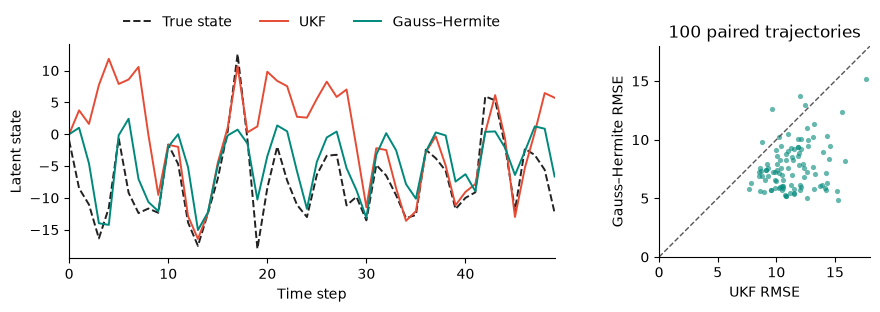

In [10]:
import matplotlib.pyplot as plt

def estimate(config, ys):
    with dsx.Filter(config):
        result = dsx.condition("x", model, obs_values=ys, **inputs)
    return result.states.filtered_means[:, 0]

gh_means = jax.jit(jax.vmap(lambda ys: estimate(split_config, ys)))(observations)
ukf_means = jax.jit(jax.vmap(lambda ys: estimate(UKFConfig(), ys)))(observations)
def path_rmse(means):
    return np.asarray(jnp.sqrt(jnp.mean((means - truths[:, :, 0])**2, axis=1)))

gh_error, ukf_error = path_rmse(gh_means), path_rmse(ukf_means)
assert np.isfinite(gh_error).all() and np.isfinite(ukf_error).all()
print(f"Mean trajectory RMSE: Gauss–Hermite {gh_error.mean():.2f}, UKF {ukf_error.mean():.2f}")
print(f"Relative reduction: {1 - gh_error.mean()/ukf_error.mean():.1%}")
print(f"Lower Gauss–Hermite RMSE on {(gh_error < ukf_error).sum()} of {len(gh_error)} trajectories.")

fig, (path_ax, score_ax) = plt.subplots(1, 2, figsize=(9, 3.4),
                                        gridspec_kw={"width_ratios": [2.3, 1]})
fig.subplots_adjust(left=0.08, right=0.97, top=0.82, bottom=0.19, wspace=0.3)
# Show the first 50 time points to keep individual transitions legible.
window = slice(0, 50)
for values, label, color, style in [
    (truths[0, :, 0], "True state", "#222222", "--"),
    (ukf_means[0], "UKF", "#E64B35", "-"),
    (gh_means[0], "Gauss–Hermite", "#00897B", "-"),
]:
    path_ax.plot(times[window], values[window], style, color=color, lw=1.4, label=label)
path_ax.set(xlabel="Time step", ylabel="Latent state", xlim=(0, 49))
path_ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3, frameon=False)
limit = np.ceil(max(gh_error.max(), ukf_error.max()))
score_ax.plot([0, limit], [0, limit], "--", color="#555555", lw=1)
score_ax.scatter(ukf_error, gh_error, color="#00897B", alpha=0.6, s=14, linewidth=0)
score_ax.set(xlabel="UKF RMSE", ylabel="Gauss–Hermite RMSE", xlim=(0, limit),
             ylim=(0, limit), aspect="equal", title="100 paired trajectories")
for ax in (path_ax, score_ax):
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

Across 100 trajectories generated by `dsx.simulate`, the mean trajectory RMSE was **7.71** for ten-point Gauss–Hermite and **11.38** for the default UKF, a **32.2% reduction**. Gauss–Hermite had lower error on **96 of 100** trajectories. Each dot compares the two filters on the same trajectory. Points below the diagonal favor Gauss–Hermite. Both filters can make sign errors because each represents the filtering distribution with one Gaussian. Gauss–Hermite uses ten model evaluations per transform versus three for the scalar UKF.